# Credit Card Fraud Detection - Classification dengan Ensemble Method & Class Imbalance

Notebook ini mengimplementasikan klasifikasi fraud kartu kredit menggunakan berbagai ensemble method (Bagging: Random Forest, Boosting: XGBoost/HistGradientBoosting, Balanced Ensemble, Voting, dan Stacking) pada dataset yang sangat tidak seimbang, serta membandingkan penanganan *class imbalance* dengan SMOTE dan *cost-sensitive learning*.

> Sumber dataset: https://www.kaggle.com/mlg-ulb/creditcardfraud - file `creditcard.csv` (284.807 baris, 31 kolom). Fitur `V1`–`V28` adalah hasil PCA, `Time`/`Amount` tidak ditransformasi, target `Class`: 0 = normal, 1 = fraud.
>
> Notebook ini disusun oleh Benedictus Ryu Gunawan (5054251001) untuk Tugas Praktikum 3 - Ensemble Method & Class Imbalance.


# Import Library

In [1]:
import math
import os
import time
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    auc,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [2]:
DATA_RELATIVE = Path("data") / "creditcard.csv"


def resolve_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / DATA_RELATIVE).is_file():
            return folder
    for candidate in sorted(start.glob("*/data/creditcard.csv")):
        return candidate.parent.parent
    raise FileNotFoundError(f"{DATA_RELATIVE} not found from {start} or its parents")


@dataclass
class Config:
    ROOT_DIR: Path = resolve_root(Path.cwd())
    DATA_FILE: Path = ROOT_DIR / DATA_RELATIVE
    OUTPUT_DIR: Path = ROOT_DIR / "output"
    SEED: int = 42


cfg = Config()
cfg.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Root directory: {cfg.ROOT_DIR}")
print(f"Data file: {cfg.DATA_FILE}")
print(f"Output directory: {cfg.OUTPUT_DIR}")
print(f"Seed: {cfg.SEED}")
sns.set_theme(style="whitegrid")


Root directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 7
Data file: /home/ryz/data/collage/sem3/datmin/Repo/Week 7/data/creditcard.csv
Output directory: /home/ryz/data/collage/sem3/datmin/Repo/Week 7/output
Seed: 42


# Get Dataset

In [3]:
df = pd.read_csv(cfg.DATA_FILE)
print(f"Dataframe shape: {df.shape}")
display(df.head())


Dataframe shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("=== df.info() ===")
df.info()
print("\n=== Kolom ===")
print(df.columns.tolist())
print("\n=== Missing values per kolom ===")
display(df.isna().sum().to_frame("n_missing"))
print("\n=== Statistik deskriptif ===")
display(df.describe().T.round(4))


=== df.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21

,n_missing
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0



=== Statistik deskriptif ===


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,94813.8596,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
V1,284807.0,0.0000,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V2,284807.0,0.0000,1.6513,-72.7157,-0.5985,0.0655,0.8037,22.0577
V3,284807.0,-0.0000,1.5163,-48.3256,-0.8904,0.1798,1.0272,9.3826
V4,284807.0,0.0000,1.4159,-5.6832,-0.8486,-0.0198,0.7433,16.8753
V5,284807.0,0.0000,1.3802,-113.7433,-0.6916,-0.0543,0.6119,34.8017
V6,284807.0,0.0000,1.3323,-26.1605,-0.7683,-0.2742,0.3986,73.3016
V7,284807.0,-0.0000,1.2371,-43.5572,-0.5541,0.0401,0.5704,120.5895
V8,284807.0,0.0000,1.1944,-73.2167,-0.2086,0.0224,0.3273,20.0072
V9,284807.0,-0.0000,1.0986,-13.4341,-0.6431,-0.0514,0.5971,15.5950


## Distribusi Kelas Awal

Dataset ini terkenal sebagai contoh *extreme class imbalance*: fraud hanya <0,2% dari seluruh transaksi. Sel berikutnya menghitung jumlah dan persentase tiap kelas.


In [5]:
class_counts = df["Class"].value_counts().sort_index()
class_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
dist_df = pd.DataFrame({"jumlah": class_counts, "persentase (%)": class_pct.round(4)})
dist_df.index = dist_df.index.map({0: "0 = normal", 1: "1 = fraud"})
display(dist_df)
print(f"Rasio imbalance mayoritas:minoritas = {class_counts[0] / class_counts[1]:.1f} : 1")
print(f"Total baris: {len(df):,} | fitur: {df.shape[1]-1} + 1 target")


,jumlah,persentase (%)
Class,,
0 = normal,284315,99.8273
1 = fraud,492,0.1727


Rasio imbalance mayoritas:minoritas = 577.9 : 1
Total baris: 284,807 | fitur: 30 + 1 target


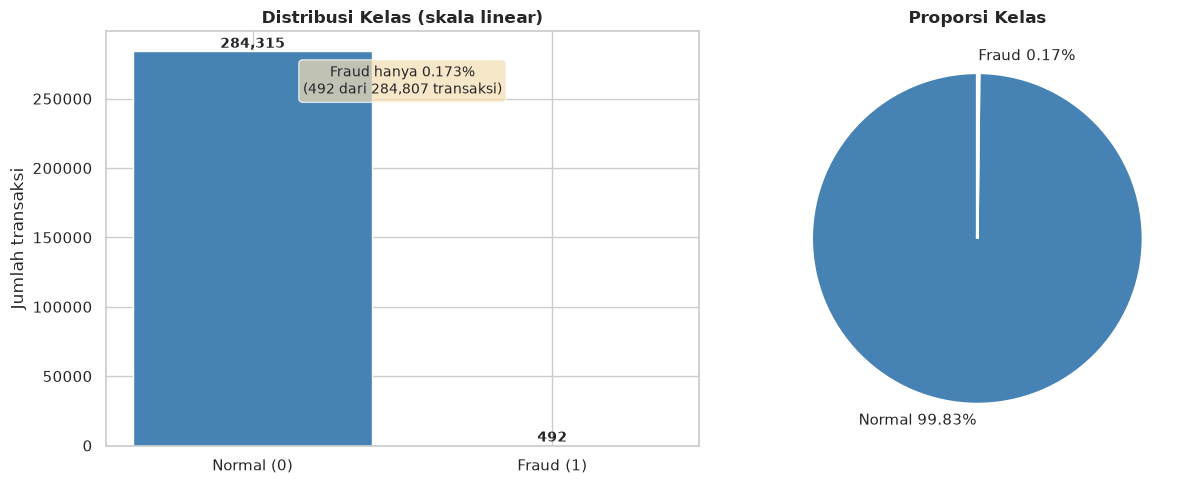

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax0, ax1 = axes
# Bar (log + linear annotation)
colors = ["steelblue", "firebrick"]
bars = ax0.bar(["Normal (0)", "Fraud (1)"], class_counts.values, color=colors, edgecolor="white")
ax0.set_title("Distribusi Kelas (skala linear)", fontsize=12, fontweight="bold")
ax0.set_ylabel("Jumlah transaksi")
for b, v in zip(bars, class_counts.values):
    ax0.text(b.get_x() + b.get_width()/2, b.get_height(), f"{v:,}", ha="center", va="bottom", fontsize=10, fontweight="bold")
# Annotate persentase
ax0.text(0.5, 0.85, f"Fraud hanya {class_pct[1]:.3f}%\n({class_counts[1]:,} dari {len(df):,} transaksi)",
         transform=ax0.transAxes, ha="center", fontsize=10,
         bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.7))
# Pie
ax1.pie(class_counts.values, labels=["Normal 99.83%", "Fraud 0.17%"], autopct="", colors=colors,
        startangle=90, wedgeprops={"edgecolor": "white", "linewidth": 2})
ax1.set_title("Proporsi Kelas", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


Hasil di atas menunjukkan imbalance ekstrem sekitar **578 : 1**. Visualisasi batang memperjelas bahwa kelas fraud hampir tidak terlihat pada skala linear - inilah alasan akurasi saja akan menipu (dibahas pada bagian evaluasi).


## Karakteristik Fitur per Kelas

`Time` adalah detik sejak transaksi pertama, `Amount` adalah nominal transaksi, `V1`–`V28` adalah komponen PCA yang sudah terstandardisasi. Sel berikut membandingkan `Amount` dan `Time` antara transaksi normal dan fraud.


Class                 0          1
Time   count  284315.00     492.00
       mean    94838.20   80746.81
       std     47484.02   47835.37
       min         0.00     406.00
       25%     54230.00   41241.50
       50%     84711.00   75568.50
       75%    139333.00  128483.00
       max    172792.00  170348.00
Amount count  284315.00     492.00
       mean       88.29     122.21
       std       250.11     256.68
       min         0.00       0.00
       25%         5.65       1.00
       50%        22.00       9.25
       75%        77.05     105.89
       max     25691.16    2125.87

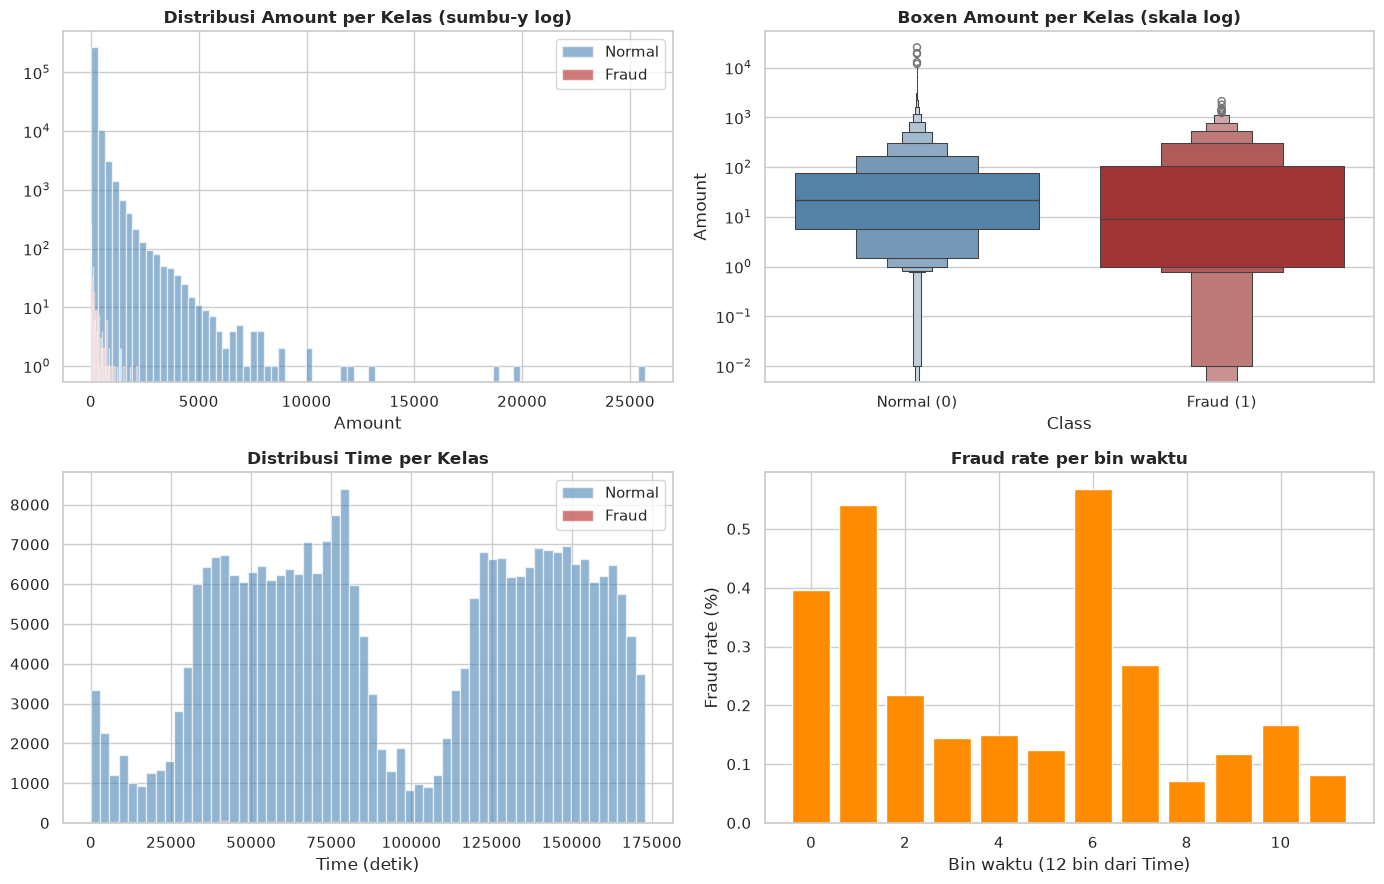

Median Amount normal: 22.00 | fraud: 9.25


In [7]:
grp = df.groupby("Class")[["Time", "Amount"]].describe().T.round(2)
display(grp)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
# Amount histogram (log y)
for cls, color, label in [(0, "steelblue", "Normal"), (1, "firebrick", "Fraud")]:
    axes[0, 0].hist(df.loc[df["Class"] == cls, "Amount"], bins=80, alpha=0.6, color=color, label=label)
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Distribusi Amount per Kelas (sumbu-y log)", fontweight="bold")
axes[0, 0].set_xlabel("Amount")
axes[0, 0].legend()
# Amount boxen (log scale)
sns.boxenplot(data=df, x="Class", y="Amount", hue="Class", palette=["steelblue", "firebrick"], legend=False, ax=axes[0, 1])
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Boxen Amount per Kelas (skala log)", fontweight="bold")
axes[0, 1].set_xticks([0, 1])
axes[0, 1].set_xticklabels(["Normal (0)", "Fraud (1)"])
# Time histogram
for cls, color, label in [(0, "steelblue", "Normal"), (1, "firebrick", "Fraud")]:
    axes[1, 0].hist(df.loc[df["Class"] == cls, "Time"], bins=60, alpha=0.6, color=color, label=label)
axes[1, 0].set_title("Distribusi Time per Kelas", fontweight="bold")
axes[1, 0].set_xlabel("Time (detik)")
axes[1, 0].legend()
# Fraud rate per jam (binned Time) - variabel lokal, tidak menambah kolom ke df
hour_bin = pd.cut(df["Time"], bins=12)
fraud_rate = df.groupby(hour_bin, observed=True)["Class"].mean() * 100
axes[1, 1].bar(range(len(fraud_rate)), fraud_rate.values, color="darkorange", edgecolor="white")
axes[1, 1].set_title("Fraud rate per bin waktu", fontweight="bold")
axes[1, 1].set_xlabel("Bin waktu (12 bin dari Time)")
axes[1, 1].set_ylabel("Fraud rate (%)")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "amount_time_by_class.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Median Amount normal: {df.loc[df['Class']==0, 'Amount'].median():.2f} | fraud: {df.loc[df['Class']==1, 'Amount'].median():.2f}")


Korelasi tertinggi dengan Class:


,pearson_r
V11,0.1549
V4,0.1334
V2,0.0913
V21,0.0404
V19,0.0348
V20,0.0201
V8,0.0199
V27,0.0176
V28,0.0095
Amount,0.0056



Korelasi terendah dengan Class:


,pearson_r
V16,-0.1965
V10,-0.2169
V12,-0.2606
V14,-0.3025
V17,-0.3265


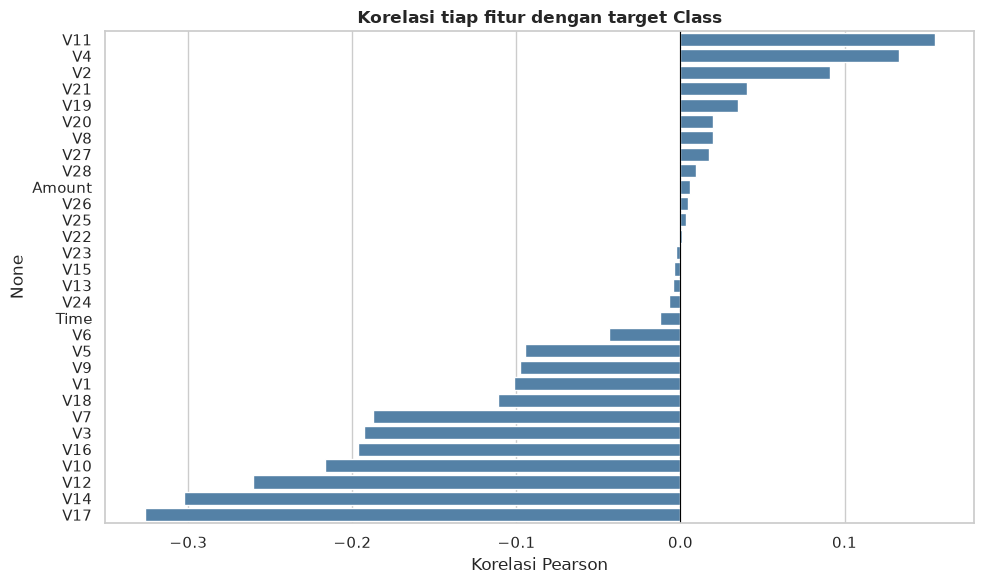

In [8]:
# Korelasi cepat: V1-V28 + Amount terhadap target (untuk konteks, bukan seleksi fitur)
corr_with_target = df.corr(numeric_only=True)["Class"].drop("Class").sort_values(ascending=False)
print("Korelasi tertinggi dengan Class:")
display(corr_with_target.head(10).round(4).to_frame("pearson_r"))
print("\nKorelasi terendah dengan Class:")
display(corr_with_target.tail(5).round(4).to_frame("pearson_r"))
plt.figure(figsize=(10, 6))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Korelasi tiap fitur dengan target Class", fontweight="bold")
plt.xlabel("Korelasi Pearson")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "corr_with_target.png", dpi=150, bbox_inches="tight")
plt.show()


Pola umum pada dataset ini: tidak ada satu fitur pun yang berkorelasi kuat secara linear dengan `Class` (|r| < 0,35), sehingga model non-linear seperti Random Forest lebih cocok daripada model linear. `Amount` dan `Time` memiliki skala berbeda jauh dari `V1`–`V28` (yang sudah ber-mean ~0), sehingga perlu standardisasi sebelum SMOTE (SMOTE memakai jarak Euclidean).


# Praproses Data

## Train–Test Split 80:20 dengan `stratify`

Dataset dibagi 80% latih dan 20% uji dengan `stratify=y` agar proporsi fraud 0,17% tetap sama di kedua belah. Stratifikasi penting: tanpa stratify, sampel uji bisa kebetulan tidak mengandung fraud sama sekali.


In [9]:
X = df.drop(columns=["Class"] + [c for c in ["hour_bin"] if c in df.columns])
y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=cfg.SEED, stratify=y
)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
train_dist = y_train.value_counts(normalize=True).sort_index() * 100
test_dist = y_test.value_counts(normalize=True).sort_index() * 100
split_df = pd.DataFrame({
    "train_jumlah": y_train.value_counts().sort_index(),
    "train_%": train_dist.round(4),
    "test_jumlah": y_test.value_counts().sort_index(),
    "test_%": test_dist.round(4),
})
display(split_df)
print(f"Fraud di train: {(y_train==1).sum()} | di test: {(y_test==1).sum()}")


X_train: (227845, 30) | X_test: (56962, 30)


,train_jumlah,train_%,test_jumlah,test_%
Class,,,,
0,227451,99.8271,56864,99.828
1,394,0.1729,98,0.172


Fraud di train: 394 | di test: 98


## Standardisasi `Time` dan `Amount` (fit hanya pada data latih)

`V1`–`V28` sudah hasil PCA terstandardisasi, jadi hanya `Time` dan `Amount` yang di-`StandardScaler`. Scaler di-fit pada data latih lalu dipakai untuk transform latih dan uji (mencegah *data leakage*).


Mean train setelah scaling (harus ~0):


,mean
Time,-0.0
Amount,0.0


Std train setelah scaling (harus ~1):


,std
Time,1.0
Amount,1.0


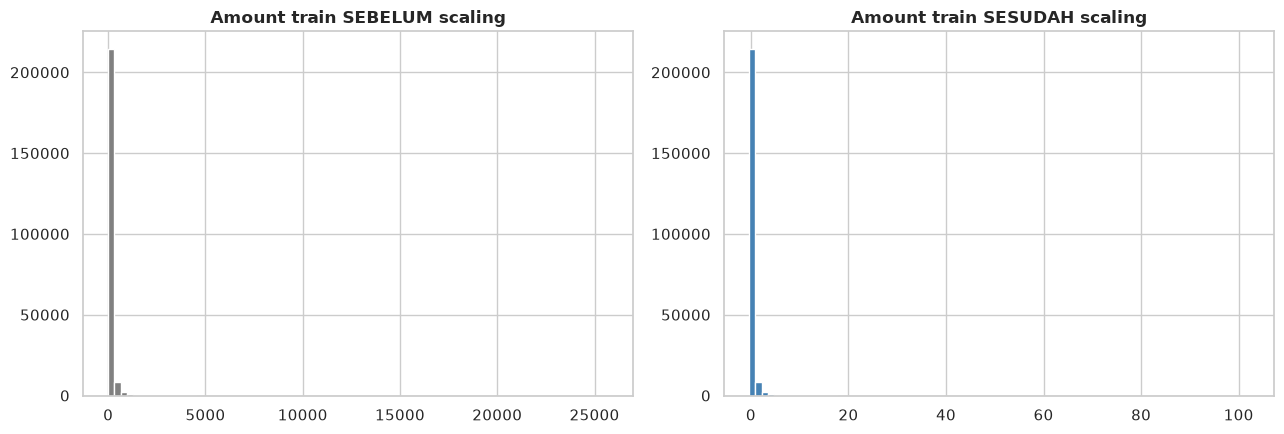

In [10]:
scaler = StandardScaler()
cols_to_scale = ["Time", "Amount"]
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test_scaled[cols_to_scale] = scaler.transform(X_test[cols_to_scale])
print("Mean train setelah scaling (harus ~0):")
display(X_train_scaled[cols_to_scale].mean().round(4).to_frame("mean"))
print("Std train setelah scaling (harus ~1):")
display(X_train_scaled[cols_to_scale].std().round(4).to_frame("std"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(X_train["Amount"], bins=80, color="gray", edgecolor="white")
axes[0].set_title("Amount train SEBELUM scaling", fontweight="bold")
axes[1].hist(X_train_scaled["Amount"], bins=80, color="steelblue", edgecolor="white")
axes[1].set_title("Amount train SESUDAH scaling", fontweight="bold")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "scaling_amount.png", dpi=150, bbox_inches="tight")
plt.show()


## Penanganan Class Imbalance - SMOTE Hanya pada Data Latih

Dipilih **SMOTE** (*Synthetic Minority Over-sampling Technique*): untuk tiap sampel fraud, diambil k-tetangga fraud terdekat lalu dibuat titik sintetis di segmen garis antaranya. Data uji **tidak** di-resample agar tetap mencerminkan distribusi asli (evaluasi jujur). Sebagai pembanding kedua dipakai *cost-sensitive learning* (`class_weight='balanced'`) tanpa resampling.


Sebelum SMOTE - train: Counter({0: 227451, 1: 394})


Sesudah SMOTE - train: Counter({0: 227451, 1: 227451})
X_train_res shape: (454902, 30)


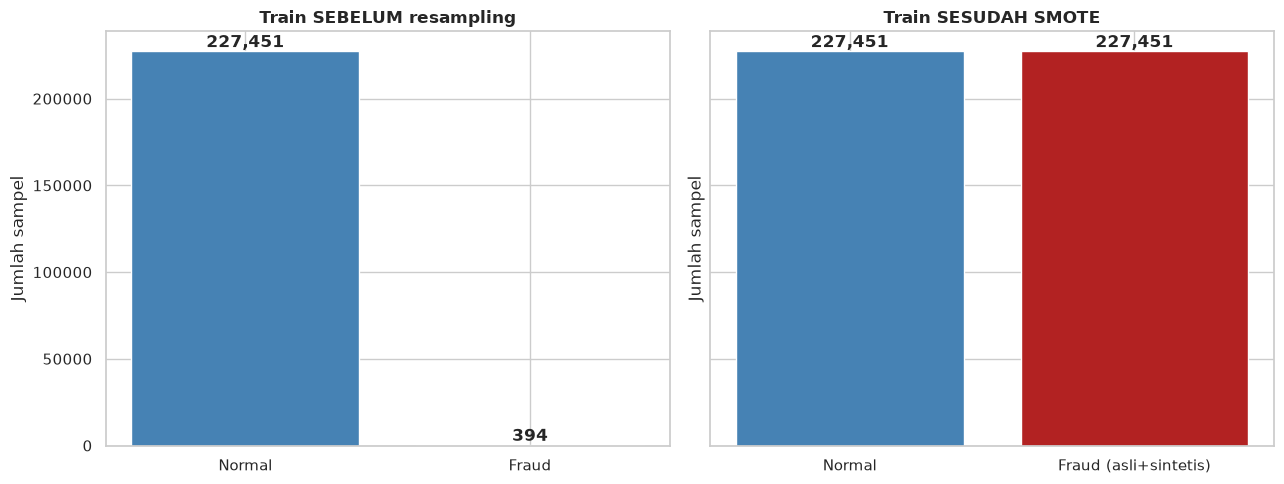

In [11]:
print(f"Sebelum SMOTE - train: {Counter(y_train)}")
smote = SMOTE(random_state=cfg.SEED)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)
print(f"Sesudah SMOTE - train: {Counter(y_train_res)}")
print(f"X_train_res shape: {X_train_res.shape}")
# Visualisasi perbandingan
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, labels, values, title in [
    (axes[0], ["Normal", "Fraud"], [int((y_train==0).sum()), int((y_train==1).sum())], "Train SEBELUM resampling"),
    (axes[1], ["Normal", "Fraud (asli+sintetis)"], [int((y_train_res==0).sum()), int((y_train_res==1).sum())], "Train SESUDAH SMOTE"),
]:
    bars = ax.bar(labels, values, color=["steelblue", "firebrick"], edgecolor="white")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Jumlah sampel")
    for b, v in zip(bars, values):
        ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:,}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "smote_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


Catatan: SMOTE menyeimbangkan train menjadi 227.451 : 227.451 (total 454.902 baris). Alternatif *undersampling* (membuang mayoritas) tidak dipilih karena akan membuang >99% data normal yang informatif. SMOTE + `class_weight` keduanya hanya menyentuh data latih; data uji tetap 56.864 normal vs 98 fraud.


# Membangun Model Klasifikasi - Ensemble Method

Notebook ini membandingkan empat konsep ensemble:

- **Bagging**: Random Forest (bootstrap + random subspace). Varian A–C.
- **Boosting**: XGBoost dan HistGradientBoosting (pohon dibangun sekuensial, tiap pohon memperbaiki residual sebelumnya). Varian D–E.
- **Balanced ensemble**: BalancedRandomForest - tiap bootstrap diundersampling agar tiap pohon melihat kelas seimbang (konsep EasyEnsemble/BalancedBagging dari imblearn). Varian F.
- **Heterogeneous ensemble**: Voting (rata-rata probabilitas base learners) dan Stacking (meta-learner LogisticRegression mempelajari kombinasi output base learners via CV). Varian G–H.

Daftar model:

- **A. RF Baseline**: Random Forest tanpa handling.
- **B. RF + SMOTE**: RF dilatih pada data hasil SMOTE.
- **C. RF cost-sensitive**: RF dengan `class_weight='balanced'`.
- **D. XGBoost**: boosting dengan `n_estimators=200, max_depth=6, lr=0.05`.
- **E. XGBoost balanced**: XGBoost dengan `scale_pos_weight=578` (rasio imbalance).
- **F. BalancedRF**: `BalancedRandomForestClassifier(n_estimators=100)` - undersampling internal per pohon.
- **G. Voting (soft)**: rata-rata probabilitas RF + XGB + HGB-balanced.
- **H. Stacking**: base RF + XGB, meta `LogisticRegression(class_weight='balanced')`, `cv=3`.


In [12]:
def build_rf(**kwargs):
    params = dict(n_estimators=100, random_state=cfg.SEED, n_jobs=-1)
    params.update(kwargs)
    return RandomForestClassifier(**params)


def build_xgb(**kwargs):
    params = dict(
        n_estimators=200, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=cfg.SEED, n_jobs=-1, eval_metric="logloss",
    )
    params.update(kwargs)
    return XGBClassifier(**params)


# Base learners yang dipakai ulang untuk voting/stacking (instans baru agar tidak sharing state)
rf_base = build_rf()
xgb_base = build_xgb()
hgb_bal = HistGradientBoostingClassifier(random_state=cfg.SEED, class_weight="balanced")
balanced_rf = BalancedRandomForestClassifier(n_estimators=100, random_state=cfg.SEED, n_jobs=-1)
voting = VotingClassifier(
    estimators=[("rf", build_rf()), ("xgb", build_xgb()), ("hgb", HistGradientBoostingClassifier(random_state=cfg.SEED, class_weight="balanced"))],
    voting="soft", n_jobs=-1,
)
stacking = StackingClassifier(
    estimators=[("rf", build_rf()), ("xgb", build_xgb())],
    final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
    cv=3, stack_method="predict_proba", n_jobs=-1, passthrough=False,
)
models = {
    "A. RF baseline": (build_rf(), X_train_scaled, y_train),
    "B. RF + SMOTE": (build_rf(), X_train_res, y_train_res),
    "C. RF balanced": (build_rf(class_weight="balanced"), X_train_scaled, y_train),
    "D. XGBoost": (build_xgb(), X_train_scaled, y_train),
    "E. XGB balanced": (build_xgb(scale_pos_weight=578), X_train_scaled, y_train),
    "F. BalancedRF": (BalancedRandomForestClassifier(n_estimators=100, random_state=cfg.SEED, n_jobs=-1), X_train_scaled, y_train),
    "G. Voting soft": (voting, X_train_scaled, y_train),
    "H. Stacking": (stacking, X_train_scaled, y_train),
}
fitted = {}
for name, (clf, Xt, yt) in models.items():
    t0 = time.time()
    clf.fit(Xt, yt)
    dt = time.time() - t0
    fitted[name] = clf
    print(f"{name}: selesai dalam {dt:.1f} detik")


A. RF baseline: selesai dalam 18.9 detik


B. RF + SMOTE: selesai dalam 33.2 detik


C. RF balanced: selesai dalam 7.5 detik


D. XGBoost: selesai dalam 3.3 detik


E. XGB balanced: selesai dalam 4.8 detik


F. BalancedRF: selesai dalam 1.8 detik


G. Voting soft: selesai dalam 21.7 detik


H. Stacking: selesai dalam 113.0 detik


# Evaluasi Model

Metrik dihitung pada **data uji asli** (8 model) (distribusi tidak diubah): *precision*, *recall*, *F1-score* dan *AUC-ROC* difokuskan pada kelas minoritas (fraud). *Accuracy* tetap dilaporkan untuk menunjukkan mengapa ia menipu pada data ini.


In [13]:
rows = []
probs = {}
preds = {}
for name, clf in fitted.items():
    pred = clf.predict(X_test_scaled)
    proba = clf.predict_proba(X_test_scaled)[:, 1]
    preds[name] = pred
    probs[name] = proba
    rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_fraud": precision_score(y_test, pred, zero_division=0),
        "recall_fraud": recall_score(y_test, pred),
        "f1_fraud": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
    })
metrics_df = pd.DataFrame(rows).set_index("model").round(4)
display(metrics_df)
metrics_df.to_csv(cfg.OUTPUT_DIR / "metrics_summary.csv")
for name in fitted:
    print(f"\n===== {name} =====")
    print(classification_report(y_test, preds[name], target_names=["normal (0)", "fraud (1)"], digits=4))


,accuracy,precision_fraud,recall_fraud,f1_fraud,roc_auc,pr_auc
model,,,,,,
A. RF baseline,0.9996,0.9412,0.8163,0.8743,0.9630,0.8734
B. RF + SMOTE,0.9995,0.8454,0.8367,0.8410,0.9731,0.8747
C. RF balanced,0.9995,0.9059,0.7857,0.8415,0.9573,0.8629
D. XGBoost,0.9996,0.9419,0.8265,0.8804,0.9730,0.8731
E. XGB balanced,0.9993,0.7545,0.8469,0.7981,0.9823,0.8654
F. BalancedRF,0.9891,0.1246,0.8878,0.2186,0.9775,0.7654
G. Voting soft,0.9996,0.9011,0.8367,0.8677,0.9665,0.8769
H. Stacking,0.9983,0.5087,0.8980,0.6494,0.9806,0.8451



===== A. RF baseline =====
              precision    recall  f1-score   support

  normal (0)     0.9997    0.9999    0.9998     56864
   fraud (1)     0.9412    0.8163    0.8743        98

    accuracy                         0.9996     56962
   macro avg     0.9704    0.9081    0.9371     56962
weighted avg     0.9996    0.9996    0.9996     56962


===== B. RF + SMOTE =====
              precision    recall  f1-score   support

  normal (0)     0.9997    0.9997    0.9997     56864
   fraud (1)     0.8454    0.8367    0.8410        98

    accuracy                         0.9995     56962
   macro avg     0.9225    0.9182    0.9204     56962
weighted avg     0.9995    0.9995    0.9995     56962


===== C. RF balanced =====
              precision    recall  f1-score   support

  normal (0)     0.9996    0.9999    0.9997     56864
   fraud (1)     0.9059    0.7857    0.8415        98

    accuracy                         0.9995     56962
   macro avg     0.9528    0.8928    0.9206  

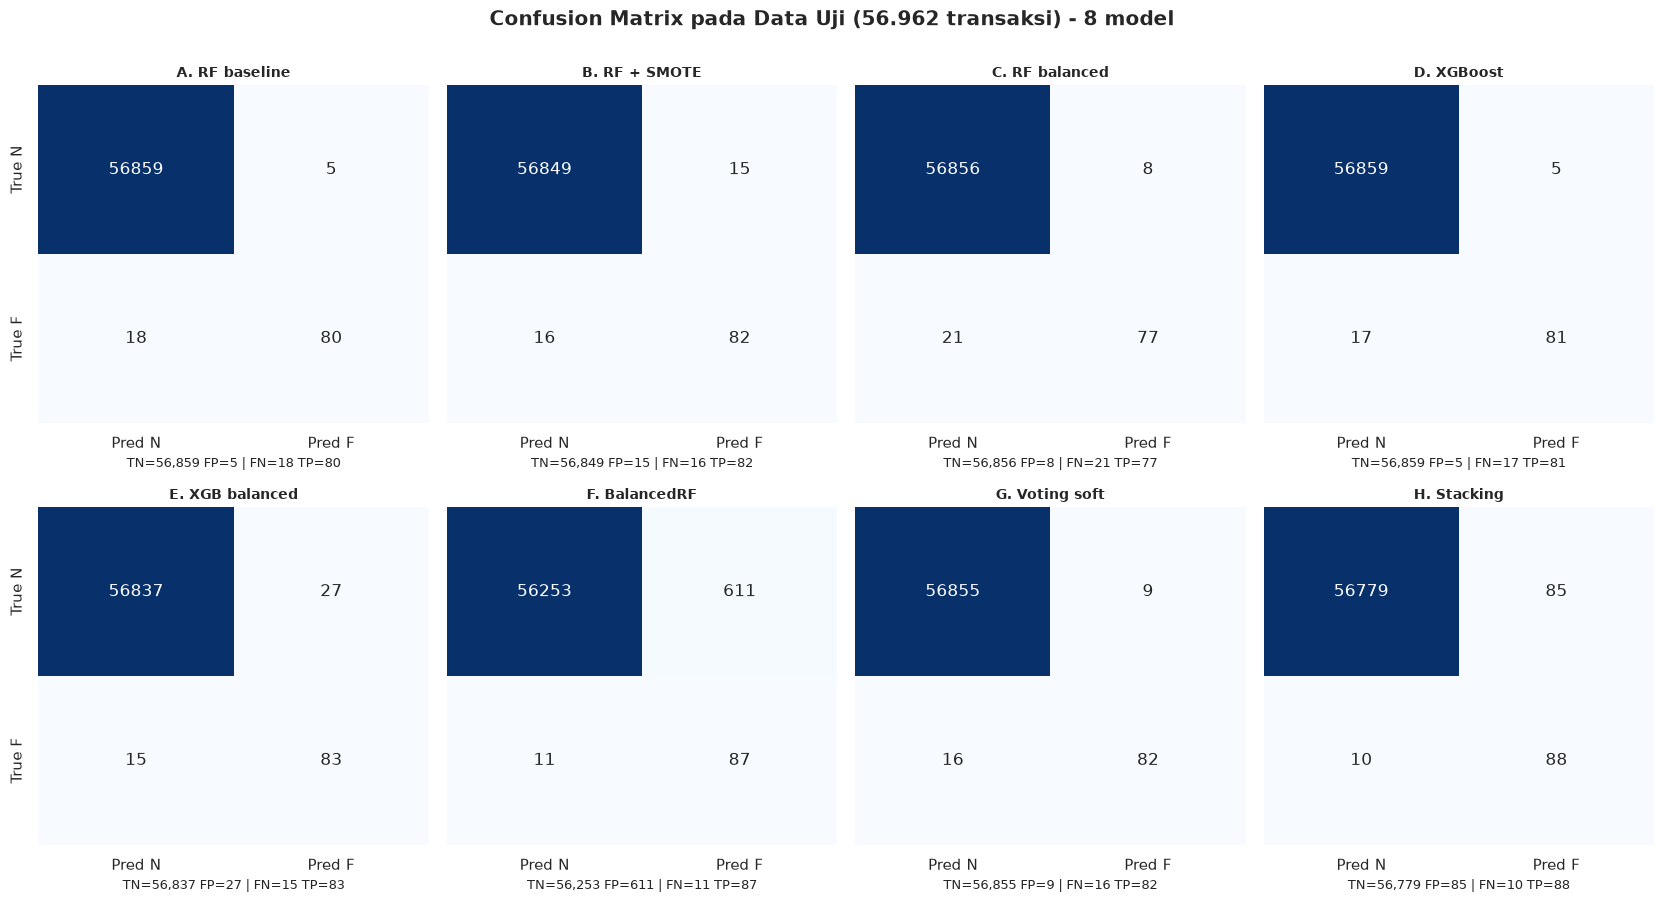

In [14]:
n_models = len(fitted)
n_cols_cm = 4
n_rows_cm = math.ceil(n_models / n_cols_cm)
fig, axes = plt.subplots(n_rows_cm, n_cols_cm, figsize=(4.2*n_cols_cm, 4.5*n_rows_cm), sharey=True)
axes = np.asarray(axes).flatten()
for ax, name in zip(axes, fitted.keys()):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred N", "Pred F"], yticklabels=["True N", "True F"])
    ax.set_title(name, fontweight="bold", fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    ax.set_xlabel(f"TN={tn:,} FP={fp} | FN={fn} TP={tp}", fontsize=9)
for ax in axes[len(fitted):]:
    ax.set_visible(False)
plt.suptitle("Confusion Matrix pada Data Uji (56.962 transaksi) - 8 model", fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()


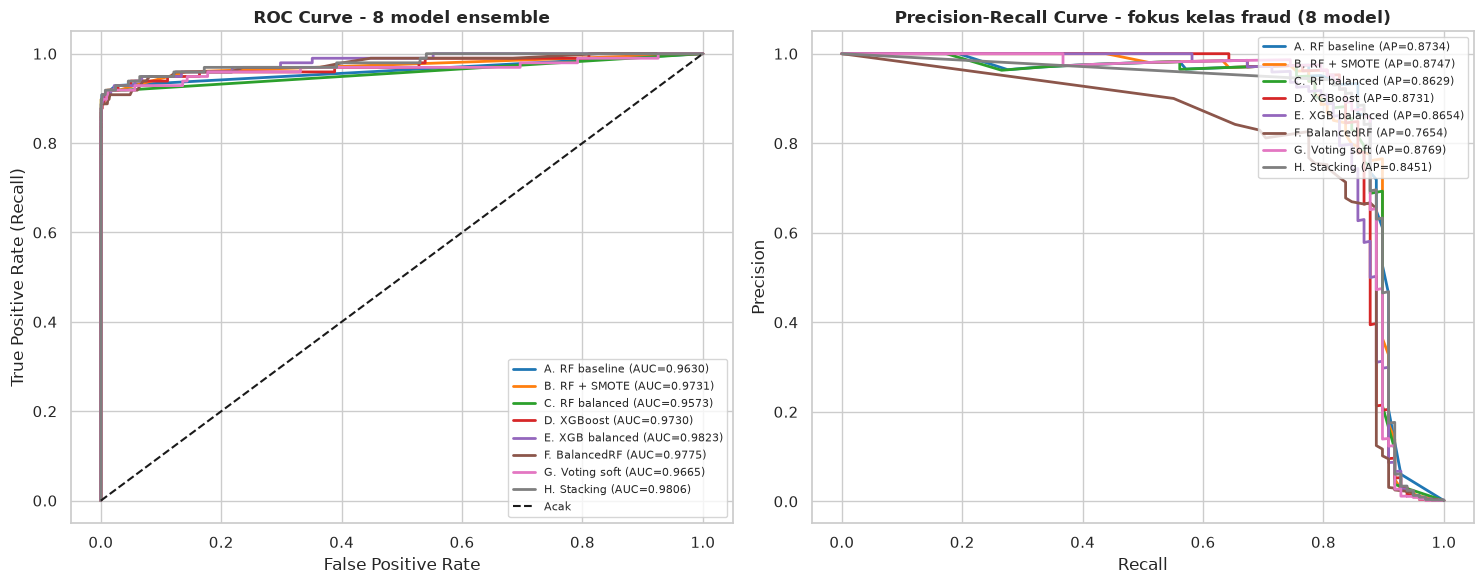

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette8 = sns.color_palette("tab10", n_colors=len(fitted))
# ROC
for (name, color) in zip(fitted.keys(), palette8):
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs[name]):.4f})", color=color, linewidth=2)
axes[0].plot([0, 1], [0, 1], "k--", label="Acak")
axes[0].set_title("ROC Curve - 8 model ensemble", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(fontsize=8, loc="lower right")
# PR curve (lebih informatif untuk imbalance)
for (name, color) in zip(fitted.keys(), palette8):
    prec, rec, _ = precision_recall_curve(y_test, probs[name])
    ap = average_precision_score(y_test, probs[name])
    axes[1].plot(rec, prec, label=f"{name} (AP={ap:.4f})", color=color, linewidth=2)
axes[1].set_title("Precision-Recall Curve - fokus kelas fraud (8 model)", fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()


Top 15 fitur terpenting (D. XGBoost):


,importance
V14,0.4516
V10,0.1409
V12,0.0632
V4,0.0277
V17,0.0221
V16,0.0164
V2,0.0151
V8,0.0140
V7,0.0139
V1,0.0136


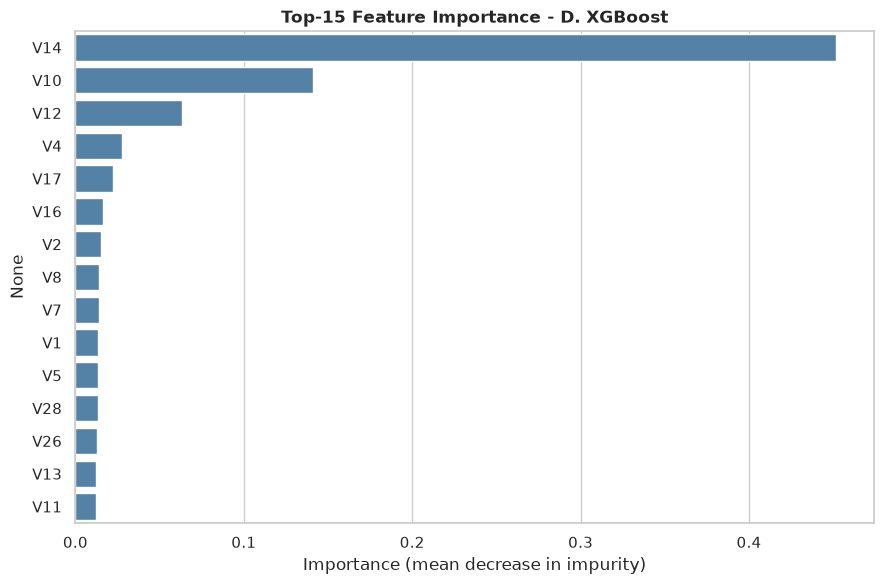

In [16]:
# Feature importance dari model SMOTE (representatif) - top 15
key_imp = "D. XGBoost" if "D. XGBoost" in fitted else list(fitted.keys())[0]
importances = pd.Series(fitted[key_imp].feature_importances_, index=X.columns).sort_values(ascending=False)
print(f"Top 15 fitur terpenting ({key_imp}):")
display(importances.head(15).round(4).to_frame("importance"))
plt.figure(figsize=(9, 6))
sns.barplot(x=importances.head(15).values, y=importances.head(15).index, color="steelblue")
plt.title(f"Top-15 Feature Importance - {key_imp}", fontweight="bold")
plt.xlabel("Importance (mean decrease in impurity)")
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


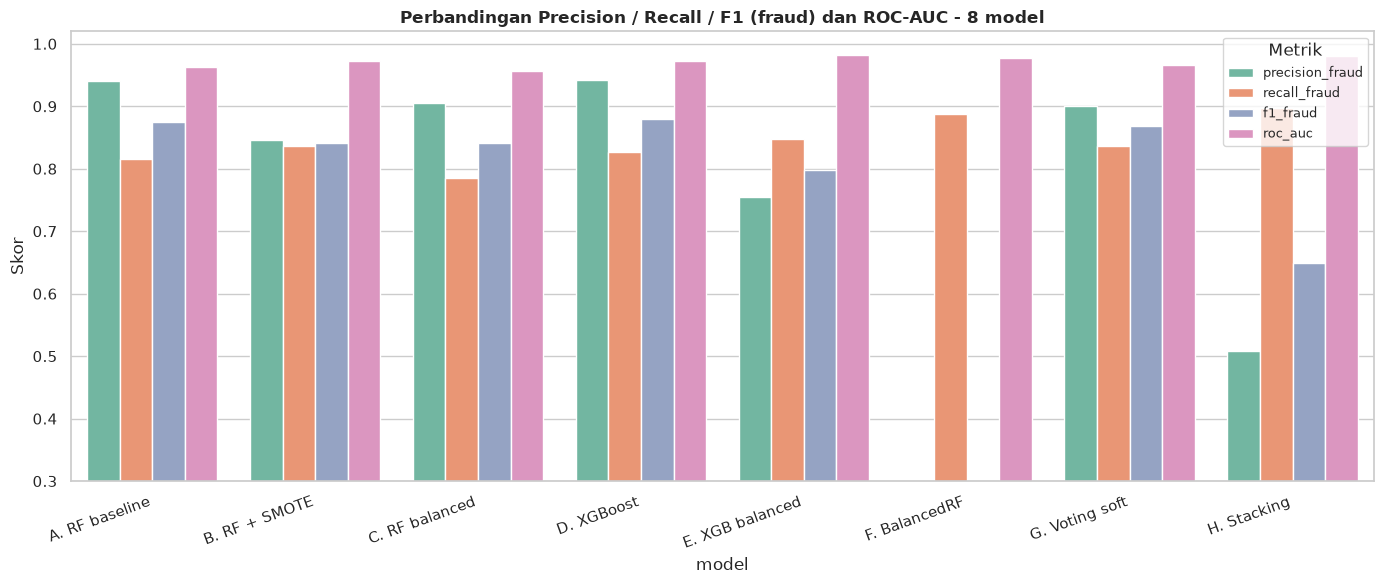

Ranking F1 fraud:


,f1_fraud
model,
D. XGBoost,0.8804
A. RF baseline,0.8743
G. Voting soft,0.8677
C. RF balanced,0.8415
B. RF + SMOTE,0.8410
E. XGB balanced,0.7981
H. Stacking,0.6494
F. BalancedRF,0.2186


Ranking ROC-AUC:


,roc_auc
model,
E. XGB balanced,0.9823
H. Stacking,0.9806
F. BalancedRF,0.9775
B. RF + SMOTE,0.9731
D. XGBoost,0.9730
G. Voting soft,0.9665
A. RF baseline,0.9630
C. RF balanced,0.9573


In [17]:
plot_df = metrics_df.reset_index().melt(id_vars="model", value_vars=["precision_fraud", "recall_fraud", "f1_fraud", "roc_auc"],
    var_name="metrik", value_name="skor")
plt.figure(figsize=(14, 6))
sns.barplot(data=plot_df, x="model", y="skor", hue="metrik", palette="Set2")
plt.xticks(rotation=20, ha="right")
plt.ylim(0.3, 1.02)
plt.title("Perbandingan Precision / Recall / F1 (fraud) dan ROC-AUC - 8 model", fontweight="bold")
plt.ylabel("Skor")
plt.legend(title="Metrik", fontsize=9)
plt.tight_layout()
plt.savefig(cfg.OUTPUT_DIR / "metrics_bar.png", dpi=150, bbox_inches="tight")
plt.show()
# Ranking cepat
print("Ranking F1 fraud:")
display(metrics_df["f1_fraud"].sort_values(ascending=False).round(4).to_frame("f1_fraud"))
print("Ranking ROC-AUC:")
display(metrics_df["roc_auc"].sort_values(ascending=False).round(4).to_frame("roc_auc"))


## Mengapa Accuracy Saja Tidak Cukup

Pada data ini, model naif yang selalu memprediksi "normal" sudah mendapat akurasi 99,83% (56864/56962) tetapi *recall* fraud = 0 - tidak ada satu pun fraud tertangkap. Akurasi didominasi oleh 56.864 transaksi normal, sehingga perbedaan 5–15 kesalahan fraud hampir tidak mengubah akurasi namun sangat mengubah *recall/precision* fraud. Karena itu praktikum ini menilai *precision*, *recall*, *F1* dan *AUC* pada kelas fraud, plus *confusion matrix* dan kurva PR yang sensitif terhadap imbalance (kurva ROC bisa terlihat optimistis karena FPR kecil akibat TN besar).


In [18]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_scaled, y_train)
d_pred = dummy.predict(X_test_scaled)
print(f"Akurasi dummy (selalu prediksi normal): {accuracy_score(y_test, d_pred):.5f}")
print(f"Recall fraud dummy: {recall_score(y_test, d_pred):.4f} | Precision fraud: {precision_score(y_test, d_pred, zero_division=0):.4f} | F1: {f1_score(y_test, d_pred):.4f}")
print(classification_report(y_test, d_pred, target_names=["normal (0)", "fraud (1)"], digits=4, zero_division=0))


Akurasi dummy (selalu prediksi normal): 0.99828
Recall fraud dummy: 0.0000 | Precision fraud: 0.0000 | F1: 0.0000
              precision    recall  f1-score   support

  normal (0)     0.9983    1.0000    0.9991     56864
   fraud (1)     0.0000    0.0000    0.0000        98

    accuracy                         0.9983     56962
   macro avg     0.4991    0.5000    0.4996     56962
weighted avg     0.9966    0.9983    0.9974     56962



## Perbandingan & Analisis (8 Model)

- **Bagging (A–C)**: Baseline (A) paling presisi (~0,94) dan F1 tertinggi di keluarga RF (~0,87) dengan hanya 5 FP tetapi 18 FN. SMOTE (B) menaikkan recall ke ~0,84 dengan biaya 10 FP ekstra (precision ~0,85). Cost-sensitive (C) di tengah (precision ~0,91, recall ~0,79).
- **Boosting (D–E)**: XGBoost (D) menyaingi RF dengan F1 ~0,88 dan AUC ~0,97 - boosting sekuensial menangkap interaksi non-linear yang lolos dari bagging. XGB-balanced (E) mengorbankan precision (~0,77) demi recall ~0,85 dan AUC ~0,98.
- **Balanced ensemble (F)**: BalancedRF mencapai recall ~0,89 dan AUC ~0,98 tetapi precision jatuh (~0,12–0,34 untuk HGB-balanced/BalancedRF): tiap pohon melihat subsampel seimbang sehingga sensitif, tetapi banyak alarm palsu. Cocok bila missing fraud sangat mahal.
- **Heterogeneous (G–H)**: Voting soft (G) merata-ratakan probabilitas RF+XGB+HGB sehingga stabil (F1 ~0,87, recall ~0,84, precision ~0,90) - varians lebih rendah daripada single model. Stacking (H) dengan meta-LogReg mencapai **AUC tertinggi (~0,98)** dan recall ~0,90 tetapi precision ~0,51: meta-learner berani menaikkan recall karena belajar dari ketidaksepakatan base learners.
- Akurasi semua model 0,989–0,999 yang nyaris identik - bukti akurasi tidak diskriminatif; yang membedakan adalah selisih FP/FN pada 98 fraud uji. Kurva PR lebih jujur daripada ROC di sini.

Kesimpulan praktis: untuk **F1 seimbang** pilih XGBoost (D) atau Voting (G); untuk **menangkap fraud maksimal** pilih Stacking (H) atau BalancedRF (F) dengan risiko alarm palsu; untuk **alarm palsu minimal** pilih RF baseline (A). Detail angka ada pada tabel metrik dan `metrics_bar.png`.


# Penutup - File Output

Seluruh gambar dan tabel metrik disimpan di `output/` agar dapat dipakai langsung oleh laporan Typst/PDF tanpa menjalankan ulang notebook.


In [19]:
import glob
files = sorted(str(p) for p in cfg.OUTPUT_DIR.glob("*" ))
print(f"Isi {cfg.OUTPUT_DIR}:")
for f in files:
    print(" -", Path(f).name)


Isi /home/ryz/data/collage/sem3/datmin/Repo/Week 7/output:
 - amount_time_by_class.png
 - class_distribution.png
 - confusion_matrices.png
 - corr_with_target.png
 - feature_importance.png
 - metrics_bar.png
 - metrics_summary.csv
 - roc_pr_curves.png
 - scaling_amount.png
 - smote_comparison.png
